# Machine Learning Assignment 2 – Classification Models

**Dataset:** Wisconsin Breast Cancer (Diagnostic), UCI via scikit-learn  
**Task:** Binary classification of tumours as malignant or benign.

This notebook trains five classifiers on one stratified train/test split and evaluates them using Accuracy, ROC-AUC, Precision, Recall, F1 and MCC. It saves fitted pipelines and a test CSV for the local Streamlit application. No deployment or publishing is performed.

## 1. Import libraries

In [1]:
import os, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
    recall_score, f1_score, matthews_corrcoef, confusion_matrix,
    ConfusionMatrixDisplay, classification_report)
from joblib import dump
warnings.filterwarnings('ignore', category=UserWarning)
RANDOM_STATE = 42
TEST_SIZE = 0.20
PROJECT_DIR = Path('.')
MODEL_DIR = PROJECT_DIR / 'model'
MODEL_DIR.mkdir(exist_ok=True)

## 2. Load and understand the dataset

The dataset contains 569 observations and 30 numeric input features. The target is encoded as `0 = malignant` and `1 = benign`.

In [2]:
dataset = load_breast_cancer(as_frame=True)
X = dataset.data.copy()
y = dataset.target.copy()
print('Dataset shape:', X.shape)
print('Number of features:', X.shape[1])
print('Target counts (0=malignant, 1=benign):')
display(y.value_counts().sort_index())
display(X.head())
print('Missing values:', int(X.isna().sum().sum()))

Dataset shape: (569, 30)
Number of features: 30
Target counts (0=malignant, 1=benign):


target
0    212
1    357
Name: count, dtype: int64

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Missing values: 0


## 3. Prepare the train/test split

Use the same stratified 80:20 split for all five models. Stratification preserves the target class proportions.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print('Training rows:', len(X_train))
print('Testing rows:', len(X_test))
print('Training class proportions:')
display(y_train.value_counts(normalize=True).sort_index())

Training rows: 455
Testing rows: 114
Training class proportions:


target
0    0.373626
1    0.626374
Name: proportion, dtype: float64

## 4. Define the five classification models

Scaling is included in pipelines for Logistic Regression, KNN and SVM because these algorithms are sensitive to feature magnitudes. The Decision Tree and Gaussian Naive Bayes models are used without scaling.

In [4]:
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ]),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'K-Nearest Neighbors': Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors=5))
    ]),
    'Gaussian Naive Bayes': GaussianNB(),
    'Support Vector Machine': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE))
    ])
}

## 5. Train and evaluate all models

Precision, Recall and F1 use class `1` (benign) as the positive class. ROC-AUC also uses the predicted probability of class `1`. MCC considers both classes.

In [5]:
def get_positive_probability(model, features):
    positive_index = list(model.classes_).index(1)
    return model.predict_proba(features)[:, positive_index]

results = []
fitted_models = {}
for model_name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probabilities = get_positive_probability(model, X_test)
    row = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, predictions),
        'AUC': roc_auc_score(y_test, probabilities),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1': f1_score(y_test, predictions, zero_division=0),
        'MCC': matthews_corrcoef(y_test, predictions)
    }
    results.append(row)
    fitted_models[model_name] = model
results_df = pd.DataFrame(results).set_index('Model')
display(results_df.round(4))

,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.9825,0.9954,0.9861,0.9861,0.9861,0.9623
Decision Tree,0.9123,0.9157,0.9559,0.9028,0.9286,0.8174
K-Nearest Neighbors,0.9561,0.9788,0.9589,0.9722,0.9655,0.9054
Gaussian Naive Bayes,0.9386,0.9878,0.9452,0.9583,0.9517,0.8676
Support Vector Machine,0.9825,0.9950,0.9861,0.9861,0.9861,0.9623


## 6. Model observations and winner



In [6]:
for model_name, model in fitted_models.items():
    row = results_df.loc[model_name]
    print(f"{model_name}: Accuracy={row['Accuracy']:.4f}, AUC={row['AUC']:.4f}, "
          f"Precision={row['Precision']:.4f}, Recall={row['Recall']:.4f}, "
          f"F1={row['F1']:.4f}, MCC={row['MCC']:.4f}")
    print('Observation:',
          f"F1 is {row['F1']:.4f}; AUC is {row['AUC']:.4f}; "
          f"MCC is {row['MCC']:.4f}. " + chr(10))
winner = results_df.sort_values(['F1', 'AUC', 'MCC'], ascending=False).index[0]
print('Overall winner (F1, then AUC and MCC):', winner)

Logistic Regression: Accuracy=0.9825, AUC=0.9954, Precision=0.9861, Recall=0.9861, F1=0.9861, MCC=0.9623
Observation: F1 is 0.9861; AUC is 0.9954; MCC is 0.9623. 

Decision Tree: Accuracy=0.9123, AUC=0.9157, Precision=0.9559, Recall=0.9028, F1=0.9286, MCC=0.8174
Observation: F1 is 0.9286; AUC is 0.9157; MCC is 0.8174. 

K-Nearest Neighbors: Accuracy=0.9561, AUC=0.9788, Precision=0.9589, Recall=0.9722, F1=0.9655, MCC=0.9054
Observation: F1 is 0.9655; AUC is 0.9788; MCC is 0.9054. 

Gaussian Naive Bayes: Accuracy=0.9386, AUC=0.9878, Precision=0.9452, Recall=0.9583, F1=0.9517, MCC=0.8676
Observation: F1 is 0.9517; AUC is 0.9878; MCC is 0.8676. 

Support Vector Machine: Accuracy=0.9825, AUC=0.9950, Precision=0.9861, Recall=0.9861, F1=0.9861, MCC=0.9623
Observation: F1 is 0.9861; AUC is 0.9950; MCC is 0.9623. 

Overall winner (F1, then AUC and MCC): Logistic Regression


## 7. Confusion matrices and classification reports


 Logistic Regression
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



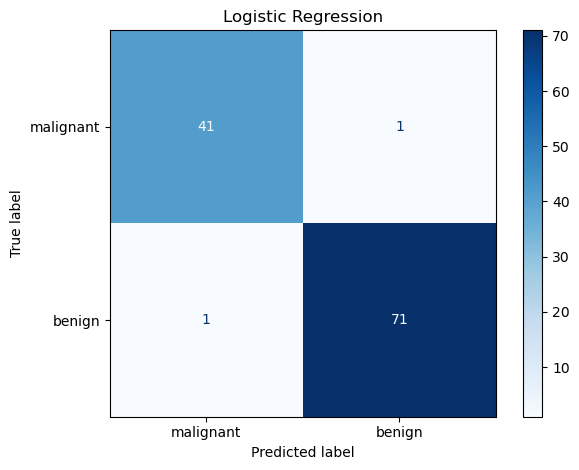


 Decision Tree
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



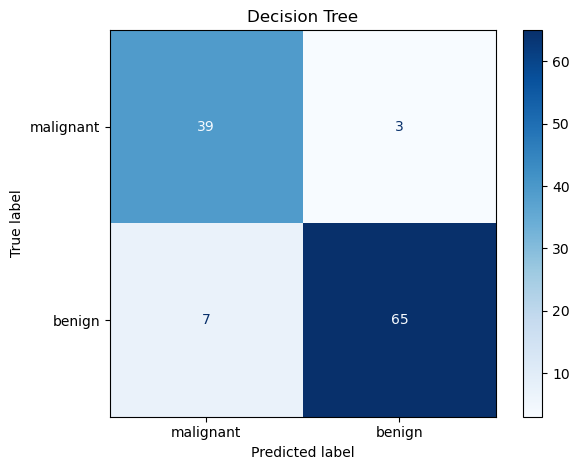


 K-Nearest Neighbors
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



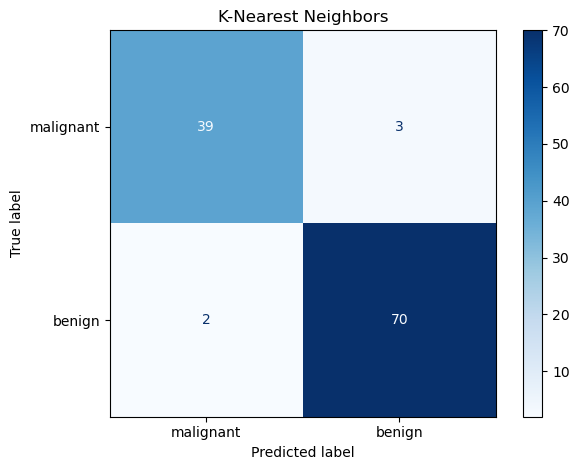


 Gaussian Naive Bayes
              precision    recall  f1-score   support

   malignant       0.93      0.90      0.92        42
      benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



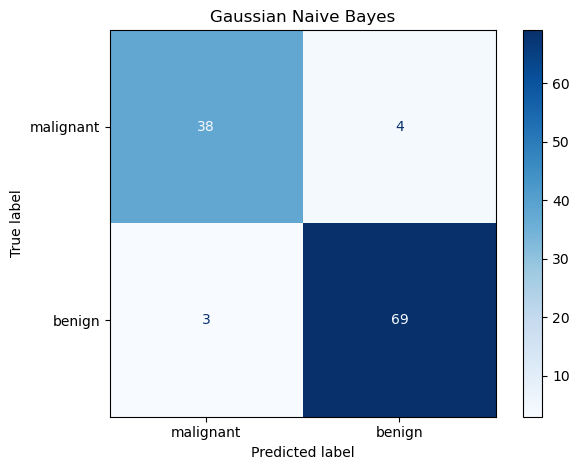


 Support Vector Machine
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



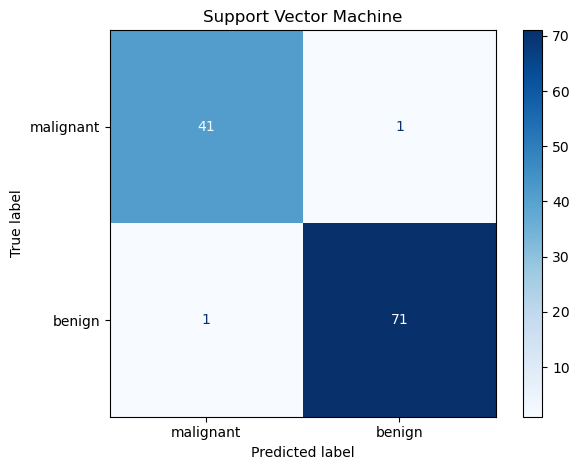

In [7]:
for model_name, model in fitted_models.items():
    predictions = model.predict(X_test)
    print('\n', model_name)
    print(classification_report(y_test, predictions,
                                labels=[0, 1],
                                target_names=['malignant', 'benign'],
                                zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, labels=[0, 1],
        display_labels=['malignant', 'benign'], cmap='Blues'
    )
    plt.title(model_name)
    plt.tight_layout()
    plt.show()

## 8. Save models, metrics and test data

The saved pipelines include preprocessing steps where needed. The app loads these artifacts and evaluates uploaded test rows; it does not retrain models.

In [8]:
from pathlib import Path
from joblib import dump
MODEL_DIR.mkdir(exist_ok=True)
file_names = {
    'Logistic Regression': 'logistic_regression.joblib',
    'Decision Tree': 'decision_tree.joblib',
    'K-Nearest Neighbors': 'knn.joblib',
    'Gaussian Naive Bayes': 'naive_bayes.joblib',
    'Support Vector Machine': 'svm.joblib'
}
for name, model in fitted_models.items():
    dump(model, MODEL_DIR / file_names[name])
results_df.to_csv('model_metrics.csv')

test_output = X_test.copy()
test_output['target'] = y_test.map({0: 'malignant', 1: 'benign'})
test_output.to_csv('test_data.csv', index=False)
full_output = X.copy()
full_output['target'] = y.map({0: 'malignant', 1: 'benign'})
full_output.to_csv('breast_cancer_wisconsin.csv', index=False)
metadata = {
    'feature_names': list(X.columns),
    'target_mapping': {'0': 'malignant', '1': 'benign'},
    'models': list(models.keys()),
    'winner': winner,
    'test_size': TEST_SIZE,
    'random_state': RANDOM_STATE
}
with open(MODEL_DIR / 'metadata.json', 'w') as file:
    json.dump(metadata, file, indent=2)
print('Saved five models, model_metrics.csv, test_data.csv and dataset CSV.')

Saved five models, model_metrics.csv, test_data.csv and dataset CSV.


## 9. Final checks

Confirming that the project contains five model files and that the test CSV contains all 30 features plus the target column.

In [9]:
print('Model files:', sorted(p.name for p in MODEL_DIR.glob('*.joblib')))
print('Test CSV shape:', test_output.shape)
print('Expected columns:', len(X.columns) + 1)
assert len(list(MODEL_DIR.glob('*.joblib'))) == 5
assert test_output.shape[1] == X.shape[1] + 1
assert test_output['target'].notna().all()
print('All final checks done.')

Model files: ['decision_tree.joblib', 'knn.joblib', 'logistic_regression.joblib', 'naive_bayes.joblib', 'svm.joblib']
Test CSV shape: (114, 31)
Expected columns: 31
All final checks done.
